# Arm 2 (`go_llm`) — how complete is the run, and can the finished part be trusted?

Arm 2 asks a language model for the GO terms of each gene, one gene after another, in dataset order. Until the run
is complete, only the genes up to some point have results. **The question this notebook answers is whether the
finished genes are a fair sample of all scoreable genes.** If they are not (for example because they are more
broadly expressed, or better annotated), then any average over them (a score, a match rate) is biased as an
estimate for the whole dataset.

Four checks, in order:
1. **Coverage**: how many genes are done, and why the others are missing.
2. **Who is missing**: the share done within groups of genes (by expression breadth, number of known true terms, ...),
   and how different the finished genes are from the missing ones.
3. **Bias check with arm 1**: arm 1 (no LLM) has results for *every* gene, so its performance on the finished genes
   versus the missing ones shows whether the finished part is easier or harder, independent of anything arm 2 did.
4. **Correction**: arm 2's scores as they are ("raw") next to the same scores re-weighted so that the finished genes
   match the whole population in breadth and annotation richness. Re-weighting only corrects differences in the
   properties used for it.

"Scoreable" = the gene has at least one non-IEA biological-process annotation, so a prediction can be scored.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
COVERAGE_FILE = Path(os.environ.get("ARM2_COVERAGE_FILE") or
                     ROOT / "data" / "go_experiment" / "match_summaries" / "arm2_coverage__go_llm_v3_freeform_true__all.json")
sns.set_theme(style="whitegrid", font_scale=1.05)

# one colour code for the whole notebook: finished genes vs genes still missing vs failed
COLORS = {"done": "#0072B2", "missing": "#BBBBBB", "problem": "#D55E00", "raw": "#E69F00", "reweighted": "#009E73"}


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


cov = json.loads(COVERAGE_FILE.read_text())
C = cov["coverage"]
print(f"file: {COVERAGE_FILE.name}   written {cov['generated_at']}")
print(f"scoreable genes: {C['n_universe']:,}   done: {C['n_done']:,} ({C['pct_done']:.1%})")
print("models used:", cov["cache_meta"].get("models"), "  code version:", cov["cache_meta"].get("code_hash_current"))
for reason, n in C["reasons"].items():
    print(f"  {reason:55s} {n:>7,}")

file: arm2_coverage__go_llm_v3_freeform_true__all.json   written 2026-10-14T06:35:42+00:00
scoreable genes: 15,944   done: 12,107 (75.9%)
models used: ['mistral-medium-3.5:latest']   code version: 5299e471e168
  done                                                     12,107
  no run yet                                                3,835
  skipped: symbol appears in the prompt (blinding)              1
  run started but not finished                                  1


## 1. Coverage: how many genes are done, and why are the others missing?

Every scoreable gene is in exactly one bar. "Done" means a finished run under the current code. The other bars say
why a gene is not done: not started yet, started but not finished (for example interrupted), failed (the answer
could not be read), skipped because the gene's symbol appears in the prompt text (the blinding check, which
protects against leaking the gene's identity), or finished under an older version of the code.

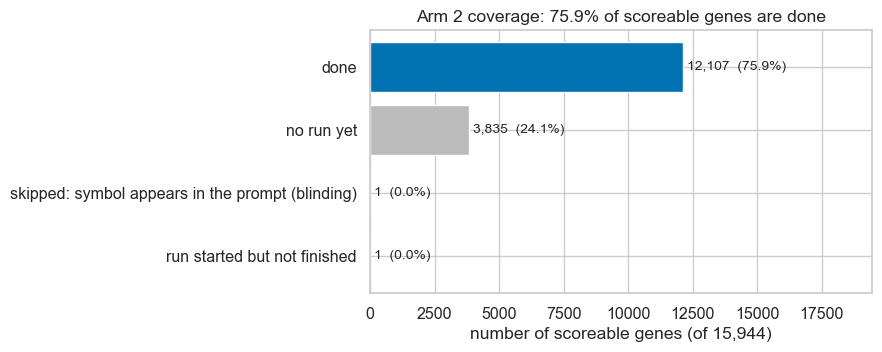

In [2]:
reasons = pd.Series(C["reasons"]).sort_values(ascending=False)
colors = [COLORS["done"] if r == "done" else COLORS["missing"] if r == "no run yet" else COLORS["problem"] for r in reasons.index]
fig, ax = plt.subplots(figsize=(9, 0.55 * len(reasons) + 1.5))
bars = ax.barh(reasons.index[::-1], reasons.values[::-1], color=colors[::-1])
for bar, v in zip(bars, reasons.values[::-1]):
    ax.text(bar.get_width() + C["n_universe"] * 0.01, bar.get_y() + bar.get_height() / 2, f"{v:,}  ({v / C['n_universe']:.1%})", va="center", fontsize=10)
ax.set_xlim(0, C["n_universe"] * 1.22)
ax.set_xlabel(f"number of scoreable genes (of {C['n_universe']:,})")
ax.set_title(f"Arm 2 coverage: {C['pct_done']:.1%} of scoreable genes are done")
fig.tight_layout(); save(fig, "arm2_c1_coverage"); plt.show()

## 2. Where is the run, and who is missing?

**Left: progress along the run order.** Genes are processed in dataset (gene ID) order. The ID order has no
biological meaning, so a run that is simply "the first part of the list" is not expected to differ from the rest
in any systematic way, which is what the next checks test.

**Right and below: the share done within groups of genes.** Each bar is one group (five equal-sized groups of the
property, or a gene family). The dashed line is the overall share done. If every bar sits near the line, the
finished genes cover all kinds of genes about equally; bars far from the line mean some kinds of genes are
over- or under-represented among the finished ones.

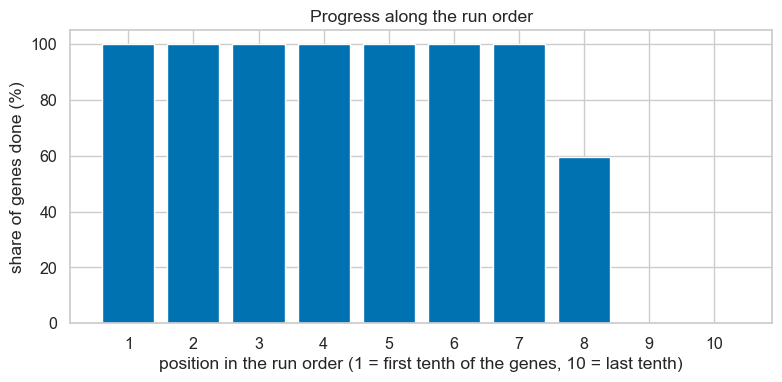

In [3]:
dec = pd.DataFrame(C["by_position_decile"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dec["decile"], dec["pct_done"] * 100, color=COLORS["done"])
ax.set_xticks(dec["decile"]); ax.set_xlabel("position in the run order (1 = first tenth of the genes, 10 = last tenth)")
ax.set_ylabel("share of genes done (%)"); ax.set_ylim(0, 105)
ax.set_title("Progress along the run order")
fig.tight_layout(); save(fig, "arm2_c2_progress"); plt.show()

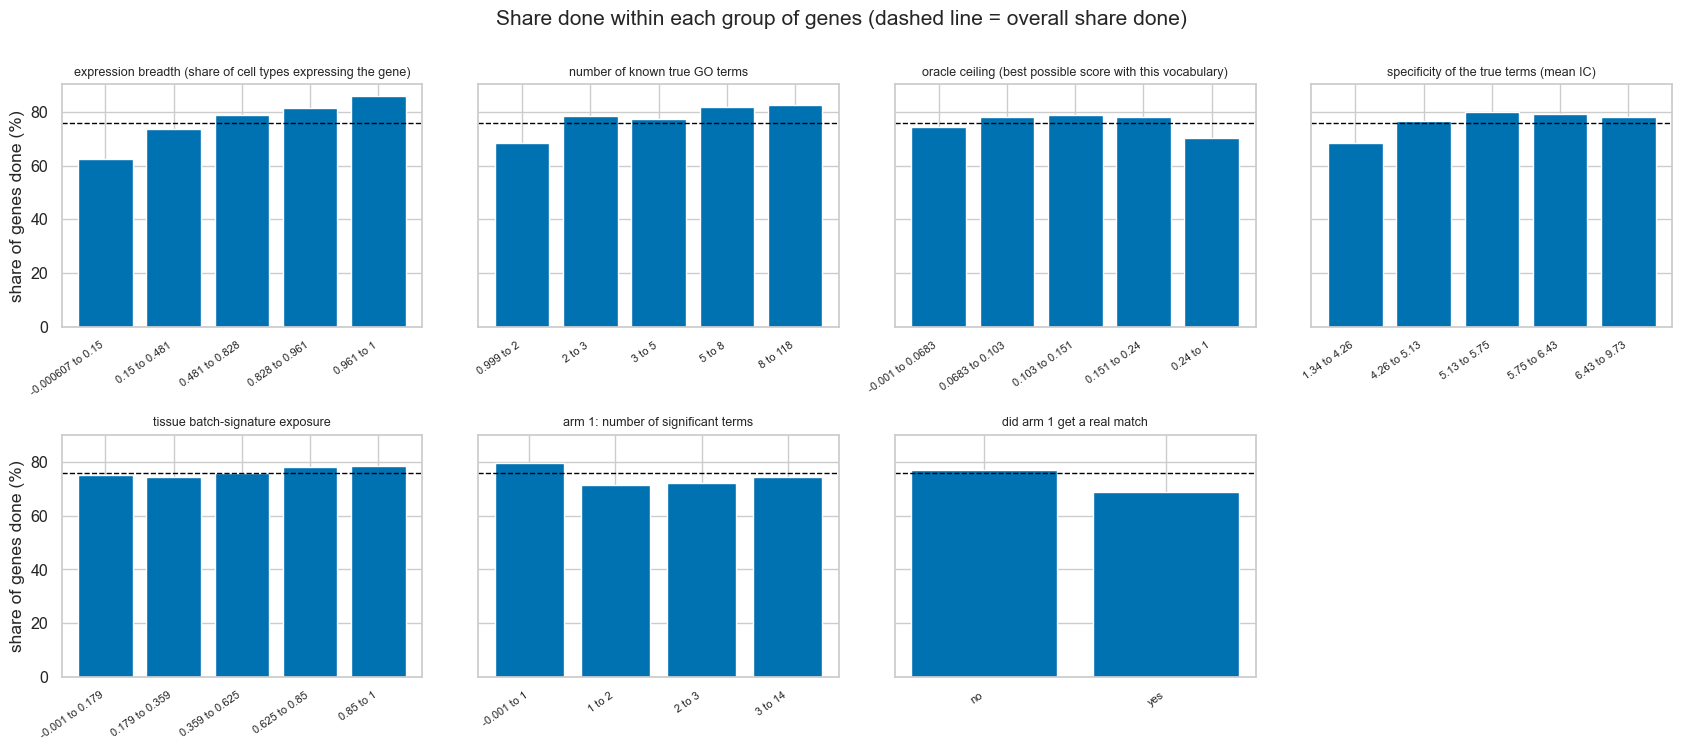

In [4]:
props = [k for k in ["breadth", "n_direct_terms", "f1_top1", "mean_true_ic", "frac_allornothing_tissues", "n_significant", "arm1_any_match"] if k in cov["by_property"]]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharey=True)
for ax, k in zip(axes.ravel(), props):
    b = pd.DataFrame(cov["by_property"][k]["bins"])
    if not len(b):
        ax.set_visible(False); continue
    ax.bar(range(len(b)), b["pct_done"] * 100, color=COLORS["done"])
    ax.axhline(C["pct_done"] * 100, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(b))); ax.set_xticklabels(b["bin"], rotation=35, ha="right", fontsize=8)
    ax.set_title(cov["by_property"][k]["name"], fontsize=9)
for ax in axes.ravel()[len(props):]:
    ax.set_visible(False)
axes[0, 0].set_ylabel("share of genes done (%)"); axes[1, 0].set_ylabel("share of genes done (%)")
fig.suptitle("Share done within each group of genes (dashed line = overall share done)", y=1.0)
fig.tight_layout(); save(fig, "arm2_c3_coverage_by_property"); plt.show()

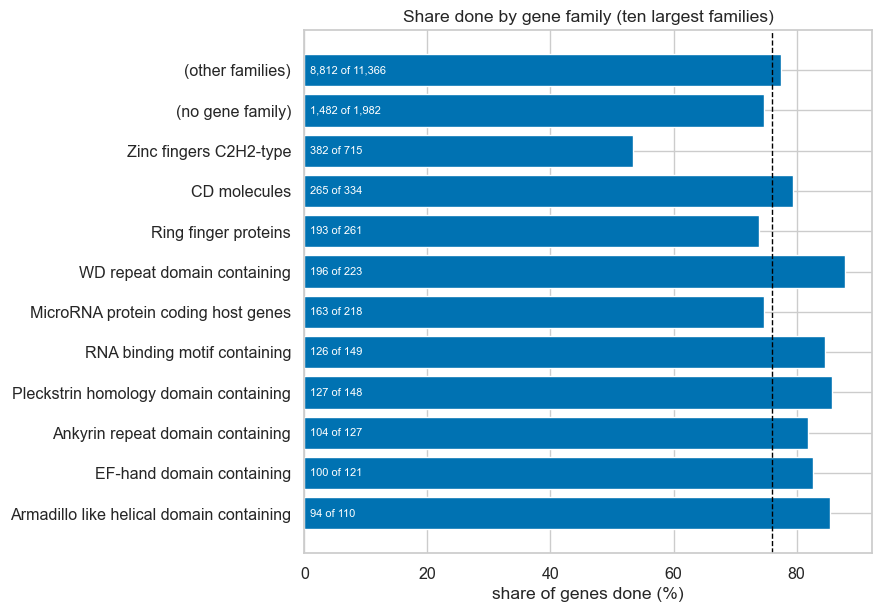

In [5]:
fam = pd.DataFrame(cov["by_property"]["family"]["bins"]).sort_values("n_universe")
fig, ax = plt.subplots(figsize=(9, 0.4 * len(fam) + 1.5))
ax.barh(fam["bin"], fam["pct_done"] * 100, color=COLORS["done"])
ax.axvline(C["pct_done"] * 100, color="black", linestyle="--", linewidth=1)
for i, (n, d) in enumerate(zip(fam["n_universe"], fam["n_done"])):
    ax.text(1, i, f"{d:,} of {n:,}", va="center", fontsize=8, color="white" if d / max(n, 1) > 0.1 else "black")
ax.set_xlabel("share of genes done (%)"); ax.set_title("Share done by gene family (ten largest families)")
fig.tight_layout(); save(fig, "arm2_c3b_coverage_by_family"); plt.show()

## 3. How different are the finished genes from the missing ones?

For each gene property: the **standardised difference** between finished and missing genes, (mean of finished minus
mean of missing) divided by the typical spread. Reading guide: values between -0.1 and 0.1 (shaded) are
negligible, around 0.2 small, 0.5 and above large. A positive value means the finished genes have more of the
property than the missing ones.

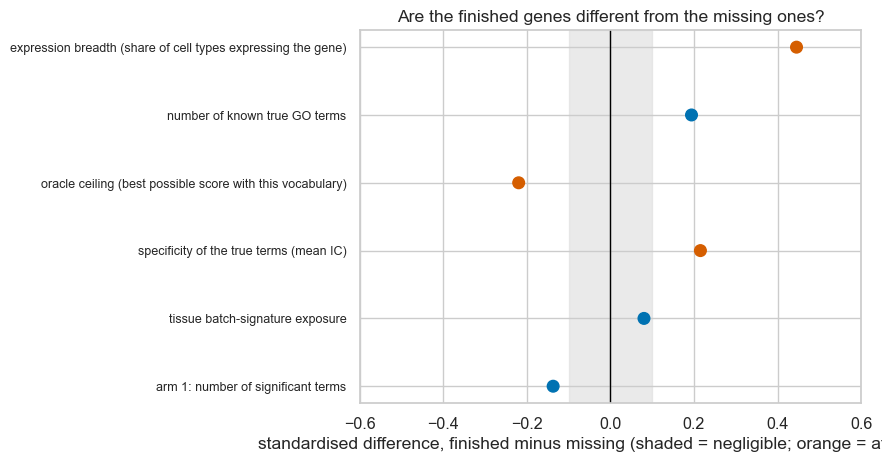

,name,mean_done,mean_missing,smd,ks_p
0,expression breadth (share of cell types expres...,0.622,0.462,0.446,0.0
1,number of known true GO terms,6.339,4.920,0.194,0.0
2,oracle ceiling (best possible score with this ...,0.164,0.200,-0.219,0.0
3,specificity of the true terms (mean IC),5.395,5.074,0.215,0.0
4,tissue batch-signature exposure,0.513,0.488,0.080,0.0
5,arm 1: number of significant terms,1.638,1.901,-0.137,0.0


In [6]:
rep = pd.DataFrame(cov["representativeness"]).dropna(subset=["smd"])
fig, ax = plt.subplots(figsize=(9, 0.55 * len(rep) + 1.5))
ax.axvspan(-0.1, 0.1, color="#DDDDDD", alpha=0.6, zorder=0)
ax.axvline(0, color="black", linewidth=1)
y = np.arange(len(rep))[::-1]
ax.scatter(rep["smd"], y, s=70, color=[COLORS["problem"] if abs(v) >= 0.2 else COLORS["done"] for v in rep["smd"]], zorder=3)
ax.set_yticks(y); ax.set_yticklabels(rep["name"], fontsize=9)
lim = max(0.6, rep["smd"].abs().max() * 1.15)
ax.set_xlim(-lim, lim)
ax.set_xlabel("standardised difference, finished minus missing (shaded = negligible; orange = at least 0.2)")
ax.set_title("Are the finished genes different from the missing ones?")
fig.tight_layout(); save(fig, "arm2_c4_standardised_differences"); plt.show()
rep[["name", "mean_done", "mean_missing", "smd", "ks_p"]].round(3)

## 4. Bias check with arm 1 (known for every gene)

Arm 1 ran on all genes, so its results show whether the finished genes were *easier* or *harder* than the rest,
without involving arm 2 at all. Each pair of bars compares the finished genes with the missing ones. The text under
each pair gives the difference and, where available, its 95% interval: an interval that includes 0 means no
detectable difference.

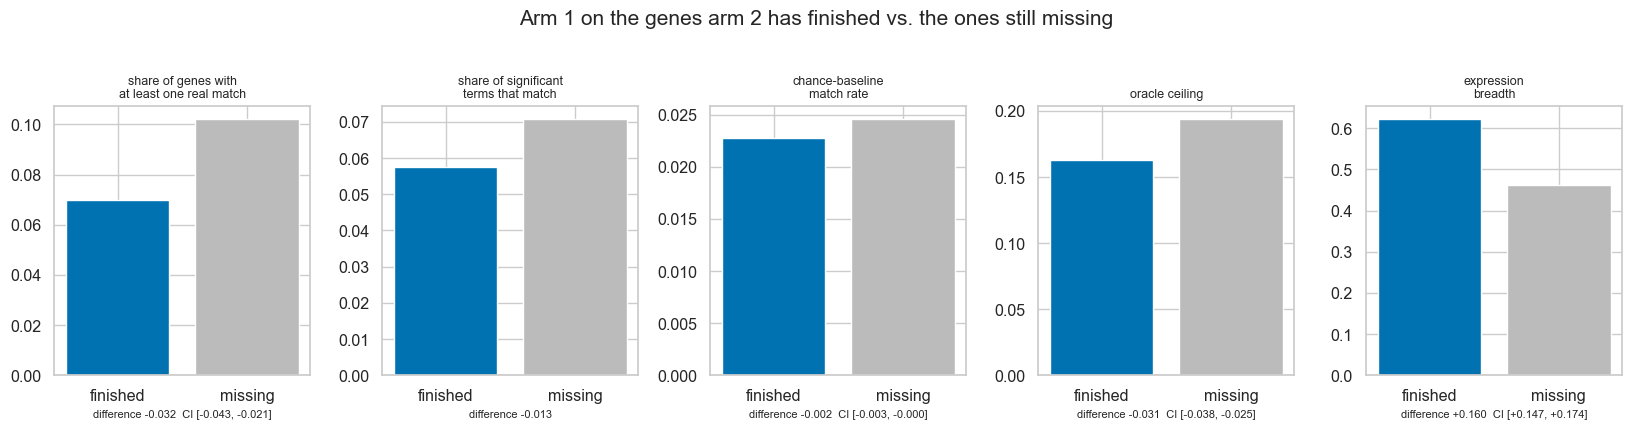

In [7]:
ref = cov["arm1_reference"]
groups = [("arm1_any_match", "share of genes with\nat least one real match"), ("arm1_match_per_term", "share of significant\nterms that match"),
          ("chance", "chance-baseline\nmatch rate"), ("f1_top1", "oracle ceiling"), ("breadth", "expression\nbreadth")]
groups = [(k, t) for k, t in groups if k in ref and ref[k]["done"] is not None and ref[k]["missing"] is not None]
fig, axes = plt.subplots(1, len(groups), figsize=(3.3 * len(groups), 4.2))
axes = np.atleast_1d(axes)
for ax, (k, title) in zip(axes, groups):
    r = ref[k]
    ax.bar(["finished", "missing"], [r["done"], r["missing"]], color=[COLORS["done"], COLORS["missing"]])
    ax.set_title(title, fontsize=9)
    ci = f"  CI [{r['ci95'][0]:+.3f}, {r['ci95'][1]:+.3f}]" if r["ci95"] else ""
    ax.set_xlabel(f"difference {r['difference']:+.3f}{ci}", fontsize=8)
fig.suptitle("Arm 1 on the genes arm 2 has finished vs. the ones still missing", y=1.02)
fig.tight_layout(); save(fig, "arm2_c5_arm1_reference"); plt.show()

## 5. Arm 2's scores: as they are, and re-weighted to the whole population

"Raw" is the plain average over the finished genes. "Re-weighted" gives each finished gene a weight so that the finished
genes match the whole population in two properties: expression breadth (five groups) and number of known true terms
(three groups). A finished gene from a group that is under-represented among the finished genes counts for more.
Bars show 95% bootstrap intervals. If raw and re-weighted agree, the incomplete coverage is not distorting that number.
If they differ, trust the re-weighted one more, but only as far as breadth and annotation richness capture the
difference between finished and missing genes.

finished genes used: 12,044   groups (strata): 15   effective sample size after weighting: 11,783   largest weight: 2.1
share of all genes in groups with no finished gene at all: 0.0%   groups with fewer than 20 finished genes: 0


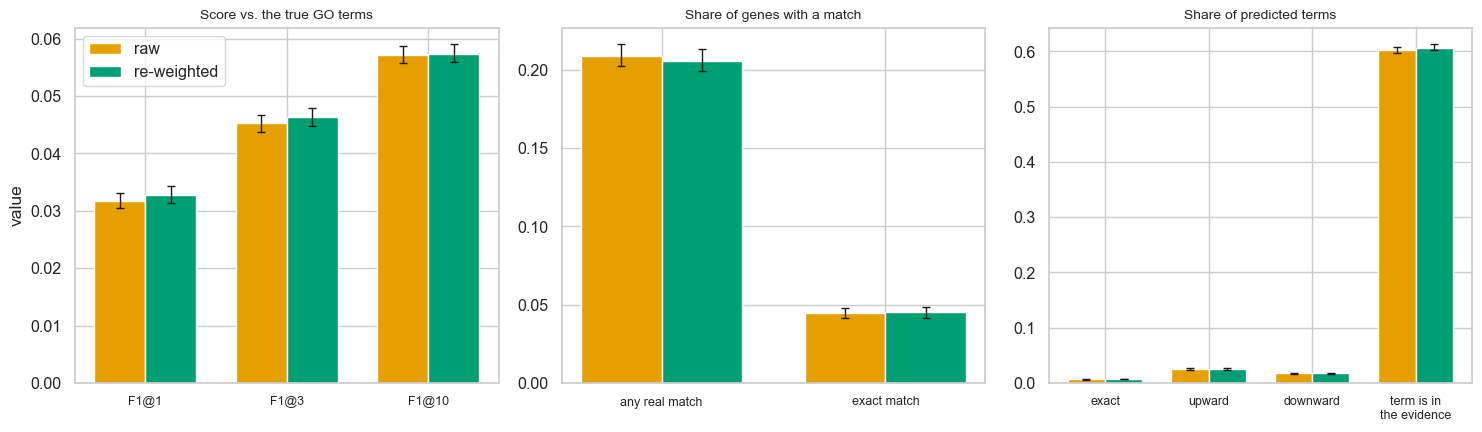

In [8]:
rw = cov["reweighting"]
if rw["status"] != "ok":
    print("Re-weighting not computed:", rw["reason"])
else:
    print(f"finished genes used: {rw['n_done_used']:,}   groups (strata): {rw['n_strata']}   "
          f"effective sample size after weighting: {rw['kish_effective_n']:,.0f}   largest weight: {rw['max_weight']:.1f}")
    print(f"share of all genes in groups with no finished gene at all: {rw['uncovered_universe_share']:.1%}   "
          f"groups with fewer than {rw['min_per_stratum']} finished genes: {len(rw['thin_strata_under_min'])}")
    M = rw["metrics"]
    panels = [("Score vs. the true GO terms", ["f1_at_1", "f1_at_3", "f1_at_10"], ["F1@1", "F1@3", "F1@10"]),
              ("Share of genes with a match", ["gene_any_match", "gene_any_exact"], ["any real match", "exact match"]),
              ("Share of predicted terms", ["share_exact", "share_upward", "share_downward", "share_in_evidence_table"],
               ["exact", "upward", "downward", "term is in\nthe evidence"])]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, (title, keys, labels) in zip(axes, panels):
        x = np.arange(len(keys)); w = 0.36
        for off, which, color in [(-w / 2, "raw", COLORS["raw"]), (w / 2, "reweighted", COLORS["reweighted"])]:
            vals = np.array([M[k][which] for k in keys]); ci = np.array([M[k][f"{which}_ci95"] for k in keys])
            ax.bar(x + off, vals, width=w, color=color, label="raw" if which == "raw" else "re-weighted",
                   yerr=[vals - ci[:, 0], ci[:, 1] - vals], capsize=3, error_kw={"linewidth": 1})
        ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9); ax.set_title(title, fontsize=10)
    axes[0].legend(); axes[0].set_ylabel("value")
    fig.tight_layout(); save(fig, "arm2_c6_raw_vs_reweighted"); plt.show()
    pd.DataFrame({k: {"raw": v["raw"], "reweighted": v["reweighted"], "difference": v["reweighted"] - v["raw"]} for k, v in M.items()}).T.round(4)

## What the numbers say (computed from the data above, with the rules written out)

The text below is generated from the numbers using fixed rules, so it updates with every new export. The rules are
deliberately simple and are meant as a prompt for judgement, not a verdict.

In [9]:
lines = []
lines.append(f"{C['n_done']:,} of {C['n_universe']:,} scoreable genes are done ({C['pct_done']:.1%}).")
rep_all = pd.DataFrame(cov["representativeness"]).dropna(subset=["smd"])
big = rep_all[rep_all["smd"].abs() >= 0.2]
if C["n_done"] < 500:
    lines.append("Too few finished genes for the comparisons below to be reliable; treat them as placeholders.")
if len(big):
    for _, r in big.iterrows():
        lines.append(f"The finished genes differ in '{r['name']}' (standardised difference {r['smd']:+.2f}): "
                     f"{r['mean_done']:.3g} among finished vs {r['mean_missing']:.3g} among missing.")
else:
    lines.append("No gene property differs between finished and missing genes by 0.2 standardised units or more.")
a1 = cov["arm1_reference"].get("arm1_any_match")
if a1 and a1["ci95"]:
    if a1["ci95"][0] > 0 or a1["ci95"][1] < 0:
        direction = "easier" if a1["difference"] > 0 else "harder"
        lines.append(f"Arm 1 gets a real match for {a1['done']:.1%} of finished vs {a1['missing']:.1%} of missing genes "
                     f"(difference {a1['difference']:+.1%}, interval excludes 0): the finished genes look {direction} than the rest, "
                     f"so raw arm-2 averages are likely biased in that direction.")
    else:
        lines.append(f"Arm 1 gets a real match for {a1['done']:.1%} of finished vs {a1['missing']:.1%} of missing genes; "
                     f"the interval includes 0, so no detectable difference in difficulty.")
rw = cov["reweighting"]
if rw["status"] == "ok":
    m = rw["metrics"]["f1_at_3"]
    lines.append(f"Arm 2 F1@3: {m['raw']:.3f} raw vs {m['reweighted']:.3f} re-weighted. "
                 + ("The two intervals overlap, so coverage is not visibly distorting this score." if not (m['raw_ci95'][1] < m['reweighted_ci95'][0] or m['reweighted_ci95'][1] < m['raw_ci95'][0])
                    else "The intervals do not overlap: use the re-weighted value."))
    if rw["uncovered_universe_share"] > 0:
        lines.append(f"{rw['uncovered_universe_share']:.1%} of genes belong to groups with no finished gene, which re-weighting cannot represent.")
print("\n".join("- " + l for l in lines))

- 12,107 of 15,944 scoreable genes are done (75.9%).
- The finished genes differ in 'expression breadth (share of cell types expressing the gene)' (standardised difference +0.45): 0.622 among finished vs 0.462 among missing.
- The finished genes differ in 'oracle ceiling (best possible score with this vocabulary)' (standardised difference -0.22): 0.164 among finished vs 0.2 among missing.
- The finished genes differ in 'specificity of the true terms (mean IC)' (standardised difference +0.22): 5.4 among finished vs 5.07 among missing.
- Arm 1 gets a real match for 7.0% of finished vs 10.2% of missing genes (difference -3.2%, interval excludes 0): the finished genes look harder than the rest, so raw arm-2 averages are likely biased in that direction.
- Arm 2 F1@3: 0.045 raw vs 0.046 re-weighted. The two intervals overlap, so coverage is not visibly distorting this score.
